# 02 · Knowledge layer, retrieval and personas

**Goal:** from the merged reviews, build everything the simulated consumers need: which reviews belong to our category, what aspects people talk about (and how positively), a search index so agents can read relevant real reviews, a small knowledge graph, and ten personas calibrated from the data.

### Methods used here, and why
| Method | Why we chose it | Known limitation |
|---|---|---|
| Category from each review's **own** title, accessories checked first | ASIN titles are unreliable (notebook 01), and "tablet case" must not count as a tablet | Keyword rules can misclassify unusual titles |
| Rule-based aspect lexicon (14 aspects) | Transparent, editable, no labelled data or heavy libraries needed | Misses paraphrases |
| Sentence sentiment = word list + negation window + star-rating fallback | Fast and explainable; the fallback avoids discarding neutral sentences | Part of the aspect sentiment comes from the stars (this matters for evaluation, notebook 04) |
| **BM25** retrieval in plain numpy (k1 = 1.5, b = 0.75) | Strong, interpretable lexical baseline for RAG; scikit-learn has no build for the newest Python versions | Lexical only: no semantic similarity. Embeddings are a Milestone 2 upgrade behind the same `.search()` interface |
| Knowledge graph as plain JSON (product → aspect edges) | Stores only relations the reviews actually support; no graph library needed | Small graph (products and aspects only) |
| Personas from keyword clusters; influencer = top 10% helpful votes; reviewer = top 10% review length | Follows the proposal's agent types; weights, shares and satisfaction are **computed**, not invented | One review can match several personas, so shares do not sum to 100% |
| `LOW DATA` flag below 30 reviews | Better to say "not enough data" than to invent numbers | - |


In [1]:
# --- Setup (works in local Jupyter and on Colab) ---------------------------------------------
# Colab: run these once in a cell above, then restart if asked:
#   !git clone https://github.com/YOUR_USERNAME/mirofish-consumer-simulation.git
#   %cd mirofish-consumer-simulation
#   !pip install -r requirements.txt
import os, sys, subprocess, json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()   # repository root
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))
pd.set_option("display.width", 150); pd.set_option("display.max_columns", 30)

def run(script, *args):
    """Run one project script exactly as you would from a terminal, and show the end of its output.
    Notebooks call the scripts (instead of copying their code) so there is a single source of truth in src/."""
    r = subprocess.run([sys.executable, str(ROOT / "src" / script), "--project-dir", str(ROOT), *map(str, args)], capture_output=True, text=True)
    print(r.stdout[-2500:])
    if r.returncode != 0:
        raise RuntimeError(r.stderr[-2000:])


## Step 1 · Choose a category and build everything
We focus on **Fire tablets**: they have the most reviews, several models that compete with each other, and clear price tiers, so they suit price and competitor scenarios best.

`--list-price` is an **assumption** (the data has no prices). Replace it with a verified list price for the model and year you study, and cite where you found it.

In [2]:
run("knowledge.py", "--category", "fire_tablet", "--list-price", "49.99")

loaded 60,872 reviews from /tmp/repo/data/processed/reviews_canonical.csv
category_class title_confidence  reviews  products  mean_rating
     accessory    asin_fallback       30         1        3.500
     accessory     review_level     5847        24        4.537
  echo_speaker    asin_fallback      679         2        4.655
  echo_speaker     review_level    10919        26        4.613
   fire_tablet    asin_fallback      159         1        4.491
   fire_tablet     review_level    18977        25        4.505
       fire_tv     review_level     2549         6        4.648
kindle_ereader     review_level     4541        13        4.725
         other    asin_fallback     5117         8        4.692
         other     review_level    12054        12        4.447

category 'fire_tablet': 19,133 reviews, 25 ASINs
# Phase 3 summary (fire_tablet)

- Reviews: 19,133 | ASINs: 25 | positive (4-5 stars): 92.1%
- Titles from review level: 99.2%; ASIN fallback: 0.8%
- Aspect mentions: 43,94

In [3]:
# How every review was classified, and how confident the title source is
display(pd.read_csv("reports/category_counts.csv"))

,category_class,title_confidence,reviews,products,mean_rating
0,accessory,asin_fallback,30,1,3.500
1,accessory,review_level,5847,24,4.537
2,echo_speaker,asin_fallback,679,2,4.655
3,echo_speaker,review_level,10919,26,4.613
4,fire_tablet,asin_fallback,159,1,4.491
5,fire_tablet,review_level,18977,25,4.505
6,fire_tv,review_level,2549,6,4.648
7,kindle_ereader,review_level,4541,13,4.725
8,other,asin_fallback,5117,8,4.692
9,other,review_level,12054,12,4.447


**How to read this table.** `review_level` means the category came from the review's own title (reliable); `asin_fallback` means that review had no own title and we used the ASIN's title (flagged as less certain). The large `other` group may contain tablets whose titles our rules do not recognise. If you want a different focus, rerun with `--category kindle_ereader`, `echo_speaker` or `fire_tv`.

## Step 2 · Aspects: what do people talk about, and how positively?
Each review is split into sentences. A sentence that matches an aspect keyword gets a sentiment of +1, 0 or -1. If the sentence itself is neutral we use the review's star rating, so we do not throw information away.

,mentions,mean_sentiment,from_lexicon
aspect,,,
price,11005,0.898,0.759
kids,6569,0.918,0.678
reading,5214,0.900,0.567
ease_of_use,4577,0.945,0.875
apps,2909,0.688,0.442
screen,2402,0.746,0.599
games,2283,0.889,0.508
video,2250,0.861,0.522
speed,2103,0.574,0.712


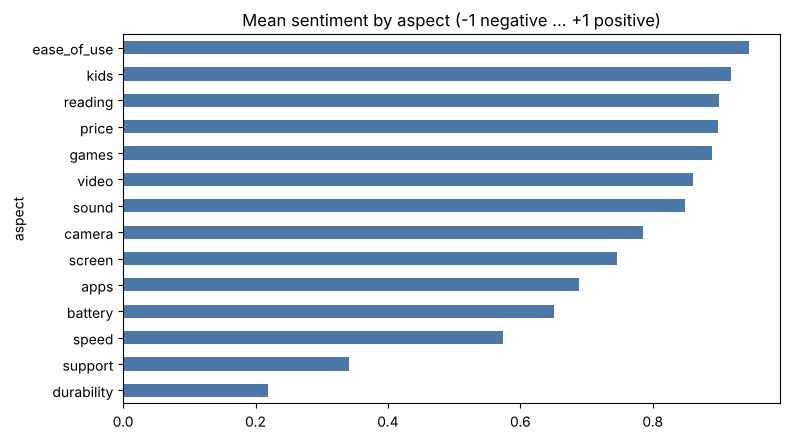

In [4]:
am = pd.read_csv("data/processed/aspect_mentions.csv")
tab = am.groupby("aspect").agg(mentions=("sentiment","size"), mean_sentiment=("sentiment","mean"),
                               from_lexicon=("sentiment_source", lambda s: (s=="lexicon").mean())).round(3).sort_values("mentions", ascending=False)
display(tab)
fig, ax = plt.subplots(figsize=(8,4.5)); tab.mean_sentiment.sort_values().plot.barh(ax=ax, color="#4c78a8")
ax.set_title("Mean sentiment by aspect (-1 negative ... +1 positive)"); plt.tight_layout(); plt.show()

**Reading the chart.** People praise price, ease of use and kids' use, but are clearly less happy about **durability, support and speed**. These low-sentiment aspects are where products can really differ, which is why notebook 04 looks at complaints and not just at praise.

## Step 3 · Retrieval (RAG): can an agent find relevant real reviews?
Agents will *read* retrieved reviews and *cite* them in conversations (notebook 05), so retrieval quality matters. Here we query the BM25 index directly.

In [5]:
from knowledge import Retriever
ret = Retriever("data/processed/retrieval_index.pkl")
top_product = pd.read_csv("data/processed/reference_outcomes.csv").sort_values("n_reviews", ascending=False).product_id.iat[0]
for q in ["battery life", "too slow and laggy", "good for kids"]:
    print(f"\nQuery: {q!r}  (product {top_product})")
    display(ret.search(q, k=3, product_id=top_product)[["rating","score","text"]].assign(text=lambda d: d.text.str[:110]))


Query: 'battery life'  (product B018Y229OU)


,rating,score,text
8568,4,11.016038,Good tablet. Like the tablet wish it had bette...
9158,4,10.447883,very good battery life. I like this device a l...
11524,4,9.775641,Good tablet but could use longer battery life....



Query: 'too slow and laggy'  (product B018Y229OU)


,rating,score,text
11467,4,11.250157,"Cheap, small and slow. It's continent for my s..."
8920,2,10.873681,Too slow for me. Too slow for me. You tube don...
14588,4,10.042661,Easy to Setup. Good for the price. Expandable ...



Query: 'good for kids'  (product B018Y229OU)


,rating,score,text
10527,4,6.355341,Good for kids. It is very good for kids who ar...
13275,4,6.231134,Good for smaller kids. This is a basic tablet ...
9713,4,6.231134,Good tablet for kids. tablet is good for older...


BM25 ranks reviews by how many query words they contain, weighted by how rare each word is and corrected for review length. It is simple and its behaviour is easy to explain, but it only matches words. A review saying "it dies by lunchtime" would not match "battery life". Semantic (embedding) retrieval would fix that; it is on the Milestone 2 list.

## Step 4 · The knowledge graph

In [6]:
kg = json.load(open("data/processed/knowledge_graph.json"))
nodes = pd.DataFrame(kg["nodes"]); edges = pd.DataFrame(kg["edges"])
print(f"{(nodes.type=='product').sum()} product nodes, {(nodes.type=='aspect').sum()} aspect nodes, {len(edges)} product-aspect edges")
display(edges.sort_values("weight", ascending=False).head(8))

25 product nodes, 14 aspect nodes, 257 product-aspect edges


,source,target,relation,weight,mean_sentiment
147,P:B018Y229OU,A:price,mentioned_with,7172,0.897
146,P:B018Y229OU,A:kids,mentioned_with,4710,0.915
144,P:B018Y229OU,A:ease_of_use,mentioned_with,2532,0.947
148,P:B018Y229OU,A:reading,mentioned_with,2493,0.880
140,P:B018Y229OU,A:apps,mentioned_with,1699,0.681
189,P:B01AHB9CN2,A:price,mentioned_with,1507,0.899
145,P:B018Y229OU,A:games,mentioned_with,1411,0.871
116,"P:B018SZT3BK,B01AHB9CN2",A:price,mentioned_with,1243,0.899


Each edge says *"this product's reviews mention this aspect N times, with this average sentiment"*. We only store relations the reviews actually support, so nothing in the graph is inferred or invented.

## Step 5 · Personas calibrated from the reviews
Every number below is **computed from the data**: share of reviews, how much each persona talks about each aspect compared with everyone else (`lift`), how satisfied they are, and their share of 4-5 star reviews (`buy_propensity`).

In [7]:
pj = json.load(open("data/processed/personas.json"))
rows = []
for name, p in pj["personas"].items():
    rows.append(dict(persona=name, reviews=p["n_reviews"], low_data=p["low_data"],
                     share=p.get("share"), positive_share=p.get("buy_propensity"), top_aspects=", ".join(p.get("top_aspects", []))))
display(pd.DataFrame(rows).set_index("persona"))

,reviews,low_data,share,positive_share,top_aspects
persona,,,,,
budget_conscious,2574,False,0.1345,0.926,"price, kids, reading, ease_of_use"
technology_enthusiast,1663,False,0.0869,0.844,"price, apps, screen, speed"
professional_user,1159,False,0.0606,0.861,"price, reading, apps, ease_of_use"
brand_loyal,561,False,0.0293,0.943,"price, reading, screen, ease_of_use"
price_sensitive,2186,False,0.1143,0.907,"price, kids, reading, apps"
camera_focused,1010,False,0.0528,0.922,"camera, price, ease_of_use, reading"
gamer,2222,False,0.1161,0.927,"games, reading, kids, price"
influencer,2243,False,0.1172,0.885,"price, reading, kids, ease_of_use"
product_reviewer,1916,False,0.1001,0.819,"price, reading, apps, screen"


### Honest notes on the personas
* They are **synthetic groups defined by what people wrote**, not real individuals and not a representative sample of the market.
* Because the data is so positive, every persona has a high positive share, so personas differ only a little in their overall satisfaction. They differ more in *which aspects they care about*.
* Nothing here uses demographics. We have no age, income or location data, and we did not invent any.

**Next:** `03_simulation_and_scenarios.ipynb` turns these personas into agents and runs price, marketing and competitor scenarios.